Draft detailed model comparison reports evaluating multiple algorithms across different metrics (accuracy, precision, recall, F1-score, AUC-ROC) and dataset splits to guide model selection and deployment decisions.

In [1]:
import numpy as np
import pandas as pd

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [3]:
np.random.seed(42)
X_num, y = make_classification(
    n_samples=2500, n_features=6, n_informative=4, n_redundant=1, random_state=42
)

In [4]:
df = pd.DataFrame(X_num, columns=['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose', 'lactate'])
df['admission_type'] = np.random.choice(['Emergency', 'Elective', 'Urgent'], size=2500, p=[0.5, 0.3, 0.2])
df.loc[df.sample(frac=0.04, random_state=42).index, 'creatinine'] = np.nan

In [5]:
num_features = ['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose', 'lactate']
cat_features = ['admission_type']
X = df[num_features + cat_features]

In [6]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

In [7]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_features)
])

In [8]:
print(f"Split sizes -> Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Split sizes -> Train: 1500 | Validation: 500 | Test: 500


In [9]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [10]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=120, learning_rate=0.05, random_state=42),
    "MLP Neural Network": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
}

In [11]:
splits = {
    "Train": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Holdout Test": (X_test, y_test)
}

In [12]:
results = []
trained_pipelines = {}

In [13]:
for model_name, estimator in candidates.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', estimator)])
    
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_time_sec = time.perf_counter() - t0
    trained_pipelines[model_name] = pipe

    # Measure single-record inference latency
    sample_row = X_test.iloc[[0]]
    t_inf = time.perf_counter()
    for _ in range(100):
        pipe.predict_proba(sample_row)
    latency_ms = ((time.perf_counter() - t_inf) / 100) * 1000

    for split_name, (X_split, y_split) in splits.items():
        probs = pipe.predict_proba(X_split)[:, 1]
        preds = (probs >= 0.5).astype(int)
        results.append({
            "Model": model_name,
            "Split": split_name,
            "Accuracy": round(accuracy_score(y_split, preds), 4),
            "Precision": round(precision_score(y_split, preds), 4),
            "Recall": round(recall_score(y_split, preds), 4),
            "F1-Score": round(f1_score(y_split, preds), 4),
            "AUC-ROC": round(roc_auc_score(y_split, probs), 4),
            "Train Time (s)": round(train_time_sec, 3),
            "Latency (ms)": round(latency_ms, 3)
        })

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [14]:
df_comparison = pd.DataFrame(results)
print(df_comparison[df_comparison["Split"] == "Holdout Test"].sort_values(by="AUC-ROC", ascending=False).to_string(index=False))

               Model        Split  Accuracy  Precision  Recall  F1-Score  AUC-ROC  Train Time (s)  Latency (ms)
  MLP Neural Network Holdout Test     0.942     0.9297  0.9558    0.9426   0.9725           1.840         4.392
HistGradientBoosting Holdout Test     0.912     0.8988  0.9277    0.9130   0.9632           0.491        10.554
       Random Forest Holdout Test     0.884     0.9064  0.8554    0.8802   0.9536           0.388        16.660
 Logistic Regression Holdout Test     0.734     0.7636  0.6747    0.7164   0.7842           0.064         3.810


In [15]:
from datetime import datetime

In [16]:
test_df = df_comparison[df_comparison["Split"] == "Holdout Test"].sort_values(by="AUC-ROC", ascending=False).reset_index(drop=True)
val_df = df_comparison[df_comparison["Split"] == "Validation"].set_index("Model")
train_df = df_comparison[df_comparison["Split"] == "Train"].set_index("Model")

In [17]:
winner = test_df.iloc[0]["Model"]
winner_auc = test_df.iloc[0]["AUC-ROC"]
winner_f1 = test_df.iloc[0]["F1-Score"]
winner_recall = test_df.iloc[0]["Recall"]
winner_latency = test_df.iloc[0]["Latency (ms)"]

In [18]:
gen_gaps = []
for m in candidates.keys():
    t_auc = train_df.loc[m, "AUC-ROC"]
    h_auc = test_df[test_df["Model"] == m]["AUC-ROC"].values[0]
    gap = round(t_auc - h_auc, 4)
    gen_gaps.append(f"{m}: Train AUC {t_auc} vs Test AUC {h_auc} (gap {gap})")
gap_summary = "\n".join(gen_gaps)

In [19]:
comparison_report = f"""Model Comparison and Selection Report
Date: {datetime.now().strftime('%Y-%m-%d %H:%M')}
Dataset Splits: Train ({len(X_train)}), Validation ({len(X_val)}), Holdout Test ({len(X_test)})

Summary and Recommendation
Selected Model: {winner}
{winner} achieved the highest Holdout Test AUC-ROC ({winner_auc}) and F1-Score ({winner_f1}), while maintaining {winner_recall:.1%} sensitivity (recall) and {winner_latency} ms per-record inference latency. It is recommended for production deployment.

Holdout Test Set Ranking
{test_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'Latency (ms)']].to_string(index=False)}

Generalization and Overfitting Check (Train vs Holdout Test)
{gap_summary}

Deployment Tradeoffs
- {winner}: Best overall discrimination and balanced precision-recall tradeoff for clinical risk scoring.
- Logistic Regression: Fastest inference speed and easiest interpretability, though lower non-linear accuracy.
- Random Forest & MLP: Competitive performance, but higher memory footprint or slower training compared to {winner}.
"""

In [20]:
report_path = "model_comparison_report.txt"
with open(report_path, "w", encoding="utf-8") as f:
    f.write(comparison_report)

In [21]:
print(comparison_report)

Model Comparison and Selection Report
Date: 2026-11-19 11:36
Dataset Splits: Train (1500), Validation (500), Holdout Test (500)

Summary and Recommendation
Selected Model: MLP Neural Network
MLP Neural Network achieved the highest Holdout Test AUC-ROC (0.9725) and F1-Score (0.9426), while maintaining 95.6% sensitivity (recall) and 4.392 ms per-record inference latency. It is recommended for production deployment.

Holdout Test Set Ranking
               Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC  Latency (ms)
  MLP Neural Network     0.942     0.9297  0.9558    0.9426   0.9725         4.392
HistGradientBoosting     0.912     0.8988  0.9277    0.9130   0.9632        10.554
       Random Forest     0.884     0.9064  0.8554    0.8802   0.9536        16.660
 Logistic Regression     0.734     0.7636  0.6747    0.7164   0.7842         3.810

Generalization and Overfitting Check (Train vs Holdout Test)
Logistic Regression: Train AUC 0.7868 vs Test AUC 0.7842 (gap 0.0026)
Random For

In [22]:
import matplotlib.pyplot as plt

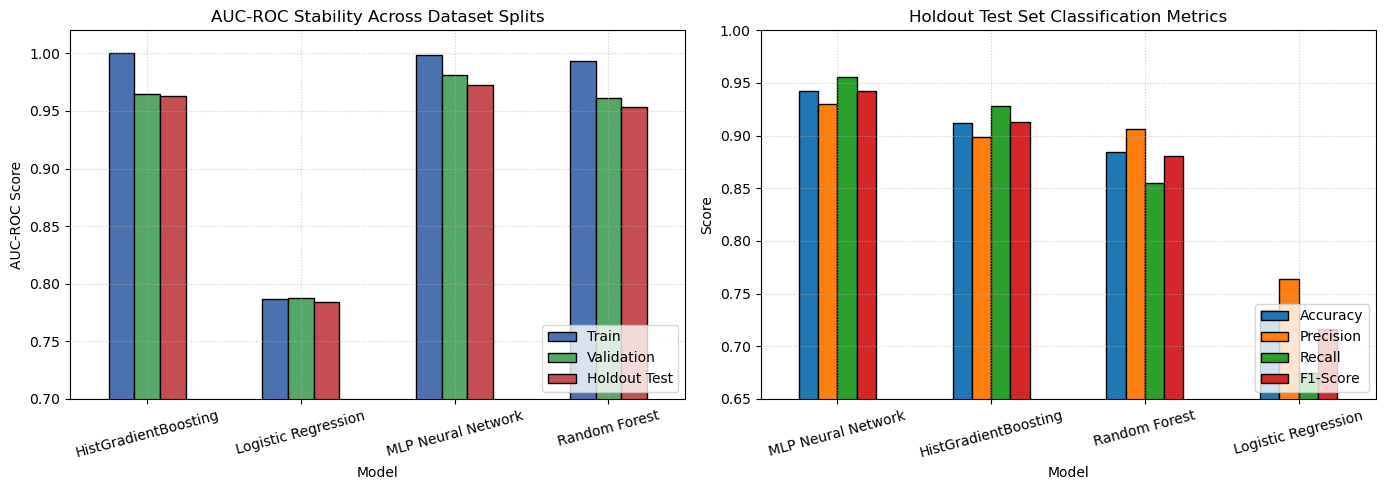

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pivot_auc = df_comparison.pivot(index="Model", columns="Split", values="AUC-ROC")[["Train", "Validation", "Holdout Test"]]
pivot_auc.plot(kind="bar", ax=axes[0], color=["#4c72b0", "#55a868", "#c44e52"], edgecolor="black")
axes[0].set_title("AUC-ROC Stability Across Dataset Splits")
axes[0].set_ylabel("AUC-ROC Score")
axes[0].set_ylim(0.70, 1.02)
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="lower right")

test_metrics = test_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score"]]
test_metrics.plot(kind="bar", ax=axes[1], edgecolor="black")
axes[1].set_title("Holdout Test Set Classification Metrics")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0.65, 1.0)
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()